# EDA — `user.csv`

Первая из трёх таблиц train-датасета. Здесь только описания исполнителей: их id, локация и наличие медкнижки. На неё дальше будут джойниться `shift` и `event` (*джойн = соединение таблиц по общему ключу, вроде SQL JOIN*), поэтому в первую очередь интересно:

1. Чистота данных: пропуски, дубли по `id`, типы.
2. Что внутри признаков (что вообще можно выжать).
3. Распределения `location_id` — насколько сбалансированы регионы (важно для группировки и кодирования категориальных признаков).

Согласно описанию полей в `DATA.md`:
- `id` — идентификатор пользователя
- `location_id` — id локации
- `is_strict_location` — пользователь явно выбрал локацию (bool)
- `has_mk` — есть ли медкнижка (bool)

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 50)
sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] = 110

In [2]:
df = pd.read_csv(r'C:\IDE\2 семестр\Хакатон\notebooks\user.csv')
print(df.shape)
df.head()

(5154, 4)


,location_id,is_strict_location,id,has_mk
0,64,False,0a66722f9259c08a6a6d78d2ea90e375,True
1,61,False,314a2bc9a488ba22a31ad0d9a0c1c26f,True
2,181,False,73f5bbba685e5e676f59a4709f04c825,True
3,234,False,50dd1bf4e4ba7ebec4a45076be1dc90c,True
4,158,False,c53805ed7cbcabe72f70da8404213552,True


## 1. Базовая проверка контракта

Контракт данных *(data contract — формальная спецификация полей и типов, прописана в `DATA.md`)* фиксирует, что должно прилетать. Проверяю что прилетело именно это.

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5154 entries, 0 to 5153
Data columns (total 4 columns):
 #   Column              Non-Null Count  Dtype
---  ------              --------------  -----
 0   location_id         5154 non-null   int64
 1   is_strict_location  5154 non-null   bool 
 2   id                  5154 non-null   str  
 3   has_mk              5154 non-null   bool 
dtypes: bool(2), int64(1), str(1)
memory usage: 90.7 KB


In [4]:
# пропуски + дубликаты
print('NaN по колонкам:')
print(df.isna().sum())
print()
print('Дубликатов строк:', df.duplicated().sum())
print('Дубликатов по id:', df['id'].duplicated().sum())

NaN по колонкам:
location_id           0
is_strict_location    0
id                    0
has_mk                0
dtype: int64

Дубликатов строк: 0
Дубликатов по id: 0


Чистые данные: пропусков нет, дублей нет, все 5154 пользователей уникальны. Это редко так бывает, обычно 1-2% мусора всегда есть. На train пайплайне `dropna` и `drop_duplicates` ничего не отрежут.

In [5]:
# id — судя по виду это md5-хеш (32 hex символа). Проверяю
lengths = df['id'].str.len().unique()
is_hex = df['id'].str.match(r'^[0-9a-f]{32}$').all()
print(f'длины id: {lengths}, все hex: {is_hex}')

длины id: [32], все hex: True


Все `id` — 32-символьные hex-строки, классический md5. Признака из этого не сделать (это просто ключ для джойна), но хорошо что формат однородный — не надо чистить.

## 2. Бинарные признаки: `is_strict_location` и `has_mk`

In [6]:
for col in ['is_strict_location', 'has_mk']:
    print(f'--- {col} ---')
    print(df[col].value_counts(dropna=False))
    print()

--- is_strict_location ---
is_strict_location
False    5154
Name: count, dtype: int64

--- has_mk ---
has_mk
True     4377
False     777
Name: count, dtype: int64



❗ **Важное наблюдение по `is_strict_location`.** В обучающей выборке колонка имеет ровно одно значение — `False` (5154 из 5154). По сути это константа.

Что это значит для модели:
- Признак с нулевой дисперсией — нулевая полезность для классификатора. В baseline (`hackaton/train/training.py`) эта колонка попадает в фичи как есть, но фактически не несёт сигнала.
- В валидационных данных значение может появиться, но если в train его нет — модель не научится его интерпретировать.
- На стороне сервиса (`predict`) `is_strict_location=True` лучше реализовать как **hard rule** *(жёсткое правило, логика «если/то» написанная руками в обход модели)*: если у юзера `is_strict_location=True` и `user.location_id != shift.location_id` — кандидата исключить из выдачи.

Договоримся с командой: либо выкинуть из фичспейса, либо проверить, что в validation она не пустая. Если пустая везде — точно выкинуть, чтобы не плодить шум.

По `has_mk`: ~85% юзеров с медкнижкой, 15% без. Это полезный сигнал, дальше посмотрю как он коррелирует с локацией.

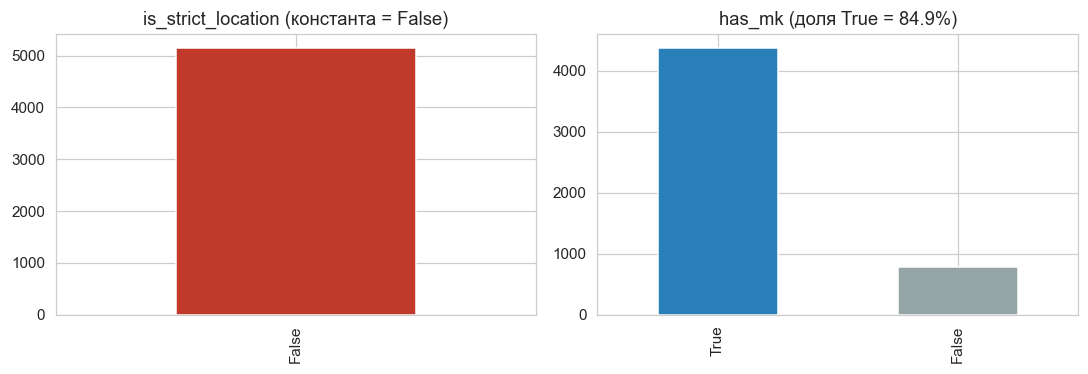

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
df['is_strict_location'].value_counts().plot.bar(ax=ax[0], color=['#c0392b'])
ax[0].set_title('is_strict_location (константа = False)')
ax[0].set_xlabel('')
df['has_mk'].value_counts().plot.bar(ax=ax[1], color=['#2980b9', '#95a5a6'])
ax[1].set_title(f'has_mk (доля True = {df["has_mk"].mean():.1%})')
ax[1].set_xlabel('')
plt.tight_layout()

## 3. `location_id` — главный категориальный признак

In [8]:
loc_counts = df['location_id'].value_counts()
print(f'уникальных локаций: {df["location_id"].nunique()}')
print(f'диапазон id: [{df["location_id"].min()}, {df["location_id"].max()}]')
print()
print('Распределение размера локаций (юзеров на локацию):')
print(loc_counts.describe())

уникальных локаций: 210
диапазон id: [1, 313]

Распределение размера локаций (юзеров на локацию):
count     210.000000
mean       24.542857
std       115.854803
min         1.000000
25%         2.000000
50%         4.000000
75%        13.000000
max      1491.000000
Name: count, dtype: float64


210 уникальных локаций при диапазоне id [1, 313] — значит id не сплошные, есть «дырки». Скорее всего `location_id` — это id из внешнего справочника (города/районы), и сюда попали только те, где есть юзеры. Для модели это не проблема, но для будущего encoding-а важно: нельзя использовать `location_id` как числовой признак (он не упорядочен).

Размеры локаций гуляют от 1 до 1491 — разброс на 3 порядка. Это типичный long-tail *(длинный хвост — у небольшого числа категорий очень много наблюдений, у большинства — мало)*.

In [9]:
print('Топ-10 локаций по числу юзеров:')
print(loc_counts.head(10).to_string())
print()
print(f'Локаций с 1 юзером:    {(loc_counts == 1).sum()}')
print(f'Локаций с <=5 юзеров:  {(loc_counts <= 5).sum()}')
print(f'Локаций с >100 юзеров: {(loc_counts > 100).sum()}')

Топ-10 локаций по числу юзеров:
location_id
234    1491
158     665
121     334
64      192
13      127
41      121
308     114
61      111
249     106
35       72

Локаций с 1 юзером:    45
Локаций с <=5 юзеров:  119
Локаций с >100 юзеров: 9


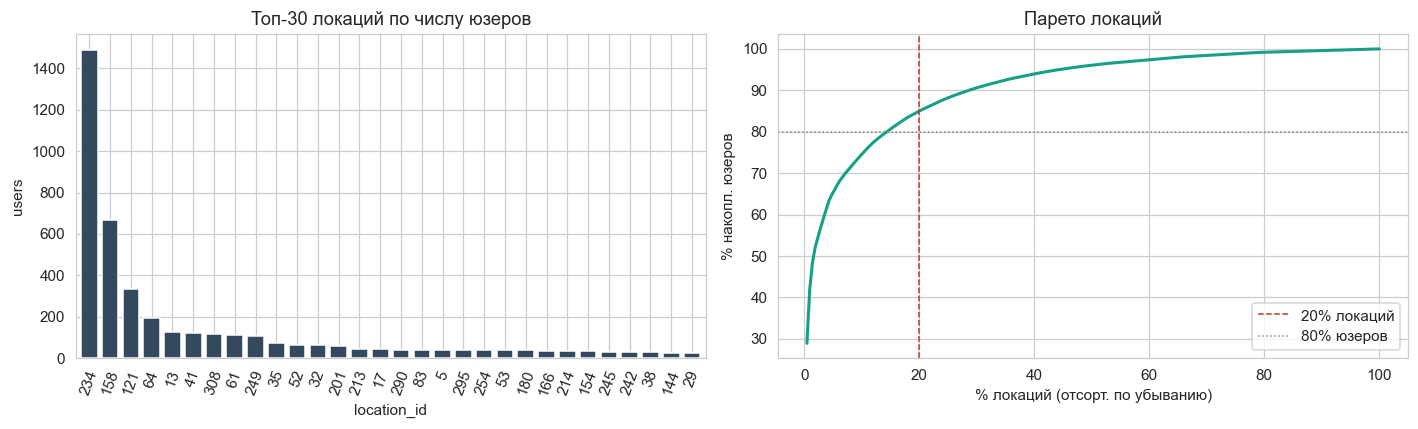

In [10]:
# Парето: сколько % локаций аккумулируют сколько % юзеров
sorted_counts = loc_counts.sort_values(ascending=False).values
cum_users = np.cumsum(sorted_counts) / sorted_counts.sum()
frac_locations = np.arange(1, len(sorted_counts) + 1) / len(sorted_counts)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))

# (1) бар-чарт топ-30
top_n = 30
loc_counts.head(top_n).plot.bar(ax=ax[0], color='#34495e', width=0.8)
ax[0].set_title(f'Топ-{top_n} локаций по числу юзеров')
ax[0].set_xlabel('location_id')
ax[0].set_ylabel('users')
ax[0].tick_params(axis='x', labelrotation=70)

# (2) Парето-кривая
ax[1].plot(frac_locations * 100, cum_users * 100, color='#16a085', lw=2)
ax[1].axvline(20, color='#c0392b', ls='--', lw=1, label='20% локаций')
ax[1].axhline(80, color='#7f8c8d', ls=':', lw=1, label='80% юзеров')
ax[1].set_xlabel('% локаций (отсорт. по убыванию)')
ax[1].set_ylabel('% накопл. юзеров')
ax[1].set_title('Парето локаций')
ax[1].legend(loc='lower right')

plt.tight_layout()

In [11]:
# точное значение для отчёта
top_20pct_locs = int(len(sorted_counts) * 0.2)
share = cum_users[top_20pct_locs - 1] * 100
print(f'Топ-20% локаций ({top_20pct_locs} из {len(sorted_counts)}) = {share:.1f}% юзеров')

# доля одной самой большой локации
biggest = loc_counts.index[0]
biggest_share = loc_counts.iloc[0] / len(df) * 100
print(f'Одна локация {biggest} = {biggest_share:.1f}% всех юзеров')

Топ-20% локаций (42 из 210) = 85.0% юзеров
Одна локация 234 = 28.9% всех юзеров


Картина классическая, но довольно жёсткая: топ-20% локаций аккумулируют ~85% юзеров, а одна локация `234` — почти треть всех (29%). Дальше полотно из мелких локаций, в 45 из них вообще по 1 юзеру.

Что с этим делать команде:
- One-hot encoding *(превратить категорию в N бинарных колонок)* по `location_id` напрямую = 210 столбцов, из которых 100+ почти пустые. Регрессия будет переобучаться на редких локациях.
- Для линейных моделей стоит сгруппировать «хвост» в категорию `location_other` (например, всё что < N юзеров).
- Альтернатива — **frequency encoding** *(заменить id категории на её частоту в train)*: тогда «крупная локация vs мелкая» становится одним числовым признаком.
- Для бустингов *(CatBoost, LightGBM — ансамбли деревьев решений)* можно скармливать `location_id` как категорию напрямую.

## 4. Связка `has_mk` × `location_id`

Гипотеза: разные локации = разный профиль работы (магазины vs склады vs пищевая). Если так — доля `has_mk=True` должна сильно гулять между локациями. Это важно, потому что в `shift` есть колонка `need_mk`, и матч `has_mk × need_mk` будет одним из ключевых признаков на стороне модели.

In [12]:
# смотрю долю has_mk только по локациям где >=20 юзеров (иначе шум)
loc_stats = (
    df.groupby('location_id')
      .agg(n=('id', 'size'), mk_rate=('has_mk', 'mean'))
      .reset_index()
)
loc_stats_signif = loc_stats[loc_stats['n'] >= 20].sort_values('mk_rate')
print(f'Локаций с n >= 20: {len(loc_stats_signif)}')
print(f'mk_rate min/median/max: {loc_stats_signif["mk_rate"].min():.2f} / '
      f'{loc_stats_signif["mk_rate"].median():.2f} / {loc_stats_signif["mk_rate"].max():.2f}')

Локаций с n >= 20: 38
mk_rate min/median/max: 0.04 / 0.94 / 1.00


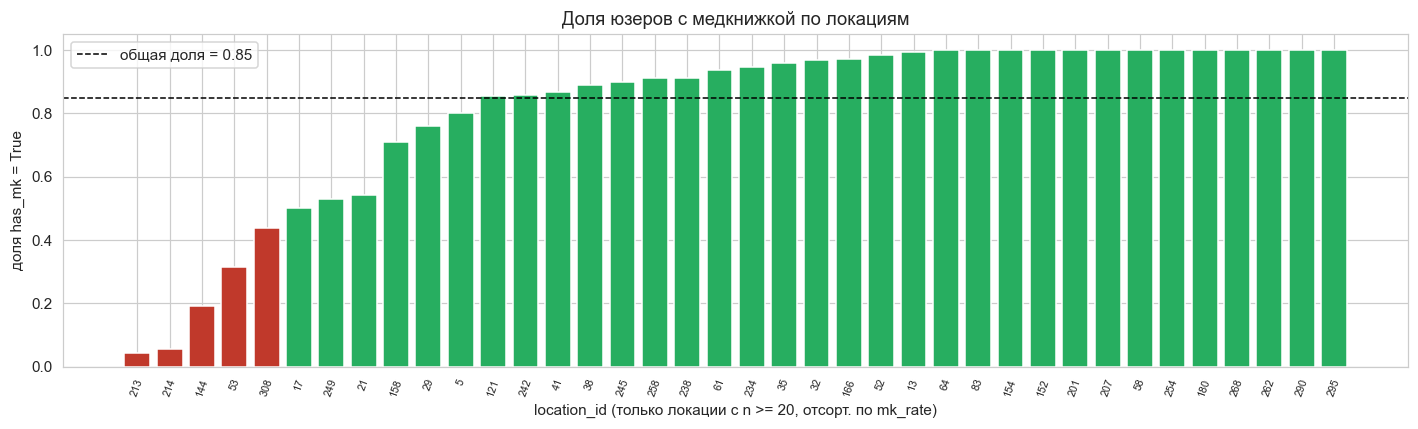

In [13]:
fig, ax = plt.subplots(figsize=(13, 4))
x = np.arange(len(loc_stats_signif))
ax.bar(x, loc_stats_signif['mk_rate'].values,
       color=['#c0392b' if v < 0.5 else '#27ae60' for v in loc_stats_signif['mk_rate']])
ax.axhline(df['has_mk'].mean(), ls='--', color='black', lw=1, label=f'общая доля = {df["has_mk"].mean():.2f}')
ax.set_xticks(x)
ax.set_xticklabels(loc_stats_signif['location_id'].astype(str), rotation=70, fontsize=7)
ax.set_ylabel('доля has_mk = True')
ax.set_xlabel('location_id (только локации с n >= 20, отсорт. по mk_rate)')
ax.set_title('Доля юзеров с медкнижкой по локациям')
ax.legend()
plt.tight_layout()

In [14]:
# топ и хвост по mk_rate — кому это интересно
print('Локации с самой низкой долей медкнижек:')
print(loc_stats_signif.head(5).to_string(index=False))
print()
print('Локации с самой высокой долей:')
print(loc_stats_signif.tail(5).to_string(index=False))

Локации с самой низкой долей медкнижек:
 location_id   n  mk_rate
         213  46 0.043478
         214  35 0.057143
         144  26 0.192308
          53  38 0.315789
         308 114 0.438596

Локации с самой высокой долей:
 location_id  n  mk_rate
         180 37      1.0
         268 22      1.0
         262 24      1.0
         290 41      1.0
         295 39      1.0


Гипотеза подтверждается чётко: `mk_rate` гуляет от ~0.04 до 1.0 в зависимости от локации. Это означает, что `location_id` сам по себе несёт сигнал о профиле работ в этой локации, а не только «географию».

Вспомогательный признак: `loc_mk_rate` — средняя доля медкнижек в локации, считается на train. Полезен для **линейных моделей** (LR), но для бустингов скорее избыточен, потому что они и так умеют выводить такие зависимости через `location_id` как категорию. Не топ-приоритет.

Главное — парный признак для матчинга юзера и смены по медкнижке. **Важный нюанс:** в baseline это сделано как `need_mk_match = (need_mk == has_mk)` — но это концептуально неправильно. Если смене медкнижка не нужна (`need_mk=False`), а у юзера она есть (`has_mk=True`), это даёт `mismatch=True` — хотя на самом деле такой юзер прекрасный кандидат (overqualified, не disqualified).

Правильная формулировка — **eligibility** *(пригодность, а не равенство)*:
```python
mk_eligible = (~need_mk) | has_mk   # юзер подходит, если медкнижка не нужна ИЛИ если она у него есть
```
Это равнозначно правилу «отсеять только тех, у кого медкнижки нет, а смене она нужна». Если хочется отдельно ловить overqualified-эффект (медкнижка у юзера, но смене не нужна — может работает хуже потому что ему «не подходит уровень»), это можно вынести в отдельный признак `is_overqualified_mk = has_mk & ~need_mk`. Но смешивать их в одну колонку через equality — это методологическая ошибка, которая искажает ранжирование.

## 5. Чек-сводка для команды

**Качество данных**
- 5154 строки, 4 колонки. Пропусков нет, дубликатов нет, все `id` уникальны и в формате md5. На input-валидацию в train-пайплайне можно не закладывать костылей под этот файл.

**Признаки**
1. `id` — ключ, не фича.
2. `is_strict_location` — **константа** (всегда `False` в train). Из фичспейса убрать. Перенести в hard rule на сервисе.
3. `has_mk` — рабочий бинарный признак, ~85/15. Сильно вариативен по локациям.
4. `location_id` — высокая кардинальность *(много уникальных значений, 210)*, жёсткий long-tail (топ-1 локация = 29% юзеров, топ-20% локаций = 85% юзеров). One-hot напрямую — плохо.

**Что предлагаю в feature engineering** (приоритеты см. в `EDA_SUMMARY.md`):
- **`is_cold_user`** — бинарный флаг: есть ли у юзера хоть одно событие в `event.csv` (VIEW/APPLY/FINISHED/CANCEL) или нет вообще. У 27% юзеров событий нет совсем. Без этого флага модель видит только `n_events = 0` и не может отличить «зомби-учётку, которая зарегистрировалась и забыла» от «свежего юзера, который просто ещё не успел». Это разные кейсы и в проде они должны получать разные скоры — флаг даёт модели возможность их различать.
- **`loc_user_count`** — для каждой локации считаем, сколько в ней юзеров (например, локация 234 → 1491, локация 17 → 3). Это **frequency encoding** *(замена id категории на её частоту в train)*. Зачем: сам по себе `location_id=234` — это просто число из справочника, для линейной модели бессмысленное. А вот «размер локации» — содержательный сигнал: в крупных локациях больше конкуренция за смены, по-другому работает динамика откликов. Одно число вместо 210 one-hot колонок.
- **Бакетизация хвоста локаций для линейных моделей.** В наших данных 45 локаций имеют ровно по 1 юзеру и ещё десятки — по 2-5. Если оставить эти локации как отдельные категории, линейная модель попытается выучить специфические веса под каждую — и переобучится на случайных особенностях этих 1-2 человек. **Бакетизация** *(объединение редких категорий в одну)* — берём все локации с числом юзеров ниже порога (например, n < 10) и схлопываем их в общую категорию `location_other`. Для бустингов *(CatBoost, LightGBM)* это не нужно — они сами справляются с редкими категориями через регуляризацию.
- **`loc_mk_rate`** — средняя доля юзеров с медкнижкой по локации. Считается на train: для локации `i` это `mean(has_mk)` среди её юзеров. У нас этот показатель гуляет от 0.04 до 1.0 — сильный доменный сигнал (ритейл-локации vs пищевые). **Но приоритет низкий** и **только для линейных моделей**: для бустингов признак избыточен — они и так умеют выводить эту зависимость самостоятельно через `location_id` как категорию (это называется **target encoding**, бустинги делают его внутри себя автоматически и корректно — out-of-fold).

**Открытые вопросы (см. `EDA_SUMMARY.md`, раздел «Открытые вопросы»)**
- Появляются ли в validation новые `location_id`, которых нет в train? OOV-кейс *(out-of-vocabulary, новые значения категории которых модель не видела)* нуждается в fallback-логике на стороне сервиса.
- Что делать в проде, если у смены `location_id` без зарегистрированных юзеров? (~1% случаев, см. `eda_shift.ipynb`)
- Стратегия для cold-start юзеров (27% от всех, см. `eda_event.ipynb`).